# <span style="color:darkblue"> Lecture 20: Text Analysis </span>

<font size = "5">

Intro text analysis

https://www.youtube.com/watch?v=IRKDrrzh4dE

# <span style="color:darkblue"> I. Setup Working Environment </span>

In [30]:

# Import SK-Learn library for machine learning functions
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS 
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import train_test_split



# Import standard data analysis packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import Kmenas
from sklearn.cluster import MiniBatchKMeans

# FAISS is not used in this notebook.
# Install it only if needed for vector search:
# !pip install faiss-cpu


# <span style="color:darkblue"> II. Data </span>

<font size = "5">

We will analyze a dataset on Amazon Reviews

https://www.kaggle.com/datasets/yasserh/amazon-product-reviews-dataset/data


In [31]:
data = pd.read_csv("data_raw/amazon_reviews.csv")

len(data)


1597

<font size = "5">

Check features

In [32]:
data.columns

Index(['id', 'asins', 'brand', 'categories', 'colors', 'dateAdded',
       'dateUpdated', 'dimension', 'ean', 'keys', 'manufacturer',
       'manufacturerNumber', 'name', 'prices', 'reviews.date',
       'reviews.doRecommend', 'reviews.numHelpful', 'reviews.rating',
       'reviews.sourceURLs', 'reviews.text', 'reviews.title',
       'reviews.userCity', 'reviews.userProvince', 'reviews.username', 'sizes',
       'upc', 'weight'],
      dtype='object')

<font size = "5">

Check text

In [33]:
reviews = data["reviews.text"]

<font size = "5">

Check rating

(array([ 42.,   0.,  34.,   0.,   0., 124.,   0., 236.,   0., 741.]),
 array([1. , 1.4, 1.8, 2.2, 2.6, 3. , 3.4, 3.8, 4.2, 4.6, 5. ]),
 <BarContainer object of 10 artists>)

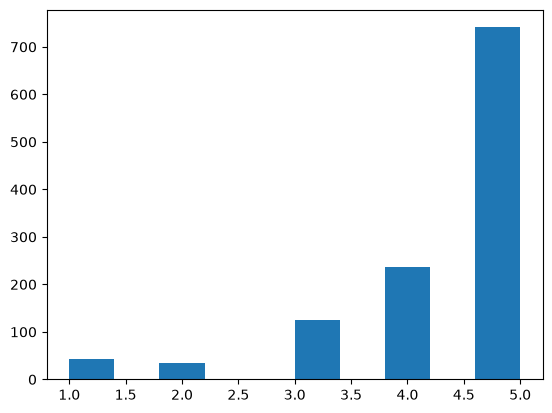

In [34]:
plt.hist(x = data["reviews.rating"])


<font size = "5">

Filter non-missing ratings data

- 26% missing data!
- Could generate selection bias in reviews

In [35]:
# Check for missing values
# A lot of reviews are missing review data
missing_values = data["reviews.rating"].isnull().sum()
percent_missing = missing_values /len(data)
print(percent_missing)

# Extract non-missing data
data_nonmissing = data[data["reviews.rating"].notnull()]

0.2629931120851597


# <span style="color:darkblue"> III. Bag of Words </span>


<font size = "5">

Stop words

- Commonly used words
- Available for different languages



In [36]:
# First ten English stop words
list(ENGLISH_STOP_WORDS)[0:10]

['again',
 'already',
 'elsewhere',
 'my',
 'themselves',
 'seeming',
 'de',
 'one',
 'whom',
 'should']

<font size = "5">

Create custom stop words

In [37]:
# Here we added Python to the list of stop words
custom_stop_words = list(ENGLISH_STOP_WORDS) + ["Python"]

# You can also create your own list
# custom_stop_words = ["and","or","how"]
custom_stop_words

['again',
 'already',
 'elsewhere',
 'my',
 'themselves',
 'seeming',
 'de',
 'one',
 'whom',
 'should',
 'nothing',
 'yourself',
 'eleven',
 'could',
 'thereby',
 'un',
 'upon',
 'its',
 'please',
 'go',
 'why',
 'even',
 'everywhere',
 'latterly',
 'thence',
 'here',
 'so',
 'almost',
 'and',
 'whereafter',
 'top',
 'five',
 'eg',
 'others',
 'myself',
 'itself',
 'what',
 'own',
 'them',
 'before',
 'thin',
 'sometimes',
 'twelve',
 're',
 'for',
 'been',
 'whenever',
 'into',
 'back',
 'too',
 'yours',
 'were',
 'with',
 'among',
 'inc',
 'herself',
 'no',
 'up',
 'still',
 'most',
 'will',
 'first',
 'alone',
 'nine',
 'toward',
 'both',
 'mill',
 'within',
 'afterwards',
 'each',
 'he',
 'etc',
 'show',
 'nevertheless',
 'bottom',
 'take',
 'might',
 'those',
 'whither',
 'sixty',
 'yet',
 'else',
 'whereas',
 'hereby',
 'as',
 'rather',
 'other',
 'along',
 'has',
 'often',
 'less',
 'which',
 'all',
 'below',
 'detail',
 'nobody',
 'very',
 'thick',
 'nowhere',
 'front',
 'ther

<font size = "5">

Count vectorizer

- Check for distinct words across all reviews
- Remove any stop words
- ```min_df``` is used to filter out words depending <br>
on how often they occur. For example, ```min_df=3``` <br>
only keeps words if they are mentioned at least 3 times

In [38]:
word_model = CountVectorizer(min_df=1,
                       stop_words=custom_stop_words)
word_model.fit(reviews)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/feature_extraction/text.py:412: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['python'] not in stop_words.
  warnings.warn(


,"stop_words stop_words: {'english'}, list, default=NoneIf 'english', a built-in stop word list for English is used.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.","['again', 'already', ...]"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (strip_accents and lowercase) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None
,"token_pattern token_pattern: str or None, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp select tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.",'(?u)\\b\\w\\w+\\b'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentword n-grams or char n-grams to be extracted. All values of n suchsuch that min_n <= n <= max_n will be used. For example an``ngram_range`` of ``(1, 1)`` means only unigrams, ``(1, 2)`` meansunigrams and bigrams, and ``(2, 2)`` means only bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word n-gram or charactern-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21Since v0.21, if ``input`` is ``filename`` or ``file``, the data isfirst read from the file and then passed to the given callableanalyzer.",'word'


<font size = "5">

Check Vocabulary

- Check in VS-Code Data Viewer
- You can use preliminary findings to decide whether <br>
to add more stop words

In [39]:
# Extract words in vocabulary and frequency
vocabulary = word_model.vocabulary_

# Convert to dataframew
frequency_words  = pd.DataFrame(vocabulary.items(),
                                columns=['Word', 'Frequency'])
                                
# Display sorted dataset                                
frequency_words.sort_values(by = "Frequency",ascending=False)

,Word,Frequency
4309,zumi,6194
4474,zooming,6193
4856,zoom,6192
5496,zombies,6191
2692,zippy,6190
...,...,...
1449,07,4
3398,04,3
484,000s,2
494,000,1


<font size = "5">

Create a dataset counting which words are used <br>
per review

- Each row is a different review
- Each column is a ${0,1}$ indicator on whether that <br>
word was mentioned
- Huge matrix!!

In [40]:
# Create X matrix
X = word_model.transform(reviews)

# Check dimension of X matrix
np.shape(X)

X_dataframe = pd.DataFrame(X)

<font size = "5">

Try it yourself!

Create a bag of words for the column "review.title".

- What are the most common words?



In [55]:
# Write your own code


# Select review titles and remove missing values
title_col = "review.title" if "review.title" in data.columns else "reviews.title"

titles = data[title_col].dropna().astype(str)

# Create the Bag of Words model
title_vectorizer = CountVectorizer(
    min_df=1,
    stop_words="english"
)

# Transform review titles into word counts
X_titles = title_vectorizer.fit_transform(titles)

# Count how often each word appears
word_counts = np.asarray(X_titles.sum(axis=0)).ravel()

# Create a table of word frequencies
title_word_counts = pd.DataFrame({
    "Word": title_vectorizer.get_feature_names_out(),
    "Count": word_counts
})

# Display the 10 most common words
title_word_counts.sort_values(
    by="Count",
    ascending=False
).head(50)



,Word,Count
740,helpful,845
1055,review,499
1289,yes,425
954,people,404
723,great,365
400,amazon,145
738,headphones,133
716,good,105
423,awesome,93
1235,use,88


# <span style="color:darkblue"> IV. Sentiment Analysis </span>

<font size = "5">
Sentiment analsys uses words to predict user ratings. <br>


- In this case we have ratings labels
- We'll use the data with nonmissing labels


In [42]:
# Write your own code

text = data_nonmissing["reviews.text"]
y    = data_nonmissing["reviews.rating"]

text_train, text_test, y_train, y_test = train_test_split(text, y,
                                                    random_state=0)

<font size = "5">

Extract vectorized X

In [43]:
# Create X matrix
word_model_train = CountVectorizer(min_df=1,
                       stop_words=custom_stop_words)
word_model_train.fit(text_train)
X_train = word_model.transform(text_train)

# Check dimension of X matrix
np.shape(X)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/feature_extraction/text.py:412: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['python'] not in stop_words.
  warnings.warn(


(1597, 6195)

<font size = "5">

We can compress the data using <br>
truncated singular value decomposition (SVD)

- This is an alternative to PCA that is better suited <br>
for sparse, binary data like text

In [44]:
svd = TruncatedSVD(n_components=3,random_state=42);
svd.fit(X_train)
X_svd_train = svd.transform(X_train)
np.shape(X_svd_train)

(882, 3)

[Text(0.5, 0, 'First Principal Component'), Text(0, 0.5, 'Rating of the gra')]

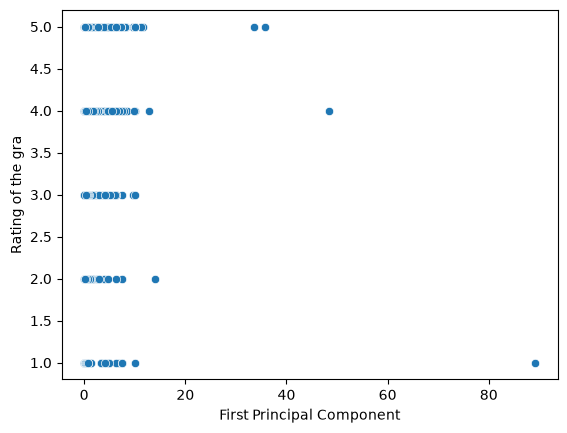

In [57]:
# Hue is used to color
ax = sns.scatterplot(x = X_svd_train[:,0],
                     y = y_train)
ax.set(xlabel='First Principal Component',
       ylabel='Rating of the gra')


<font size = "5">

Try it yourself!

Create a machine learning pipeline

- Run a support vector machine regression to predict user ratings
- What is the out-of-sample performance on the test data?
- Use your data to predict reviews that were missing
- How does the distribution of missing to non-missing reviews compare?



In [46]:
# Write your own code


from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.svm import LinearSVR
from sklearn.model_selection import train_test_split

# Keep reviews with both text and ratings
labeled = data.dropna(
    subset=["reviews.text", "reviews.rating"]
)

# Define predictor and outcome
X = labeled["reviews.text"].astype(str)
y = labeled["reviews.rating"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Create machine learning pipeline
model = make_pipeline(
    CountVectorizer(stop_words="english", min_df=1),
    TruncatedSVD(n_components=3, random_state=42),
    LinearSVR(random_state=42, max_iter=10000)
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed")




Model training completed


In [47]:

from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Predict ratings using the test data
y_pred = model.predict(X_test)

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Calculate R-squared
r2 = r2_score(y_test, y_pred)

# Display results
print("Test RMSE:", round(rmse, 3))
print("Test R-squared:", round(r2, 3))


Test RMSE: 1.091
Test R-squared: -0.357


In [48]:

# Select reviews with missing ratings but available text
missing_reviews = data[
    data["reviews.rating"].isna()
    & data["reviews.text"].notna()
].copy()

# Predict missing ratings
missing_reviews["predicted_rating"] = model.predict(
    missing_reviews["reviews.text"].astype(str)
)

# Display the results
print("Number of missing ratings:", len(missing_reviews))

missing_reviews[
    ["reviews.text", "predicted_rating"]
].head(10)


Number of missing ratings: 420


,reviews.text,predicted_rating
5,"My previous kindle was a DX, this is my second...",5.0
6,Allow me to preface this with a little history...,5.0
7,Just got mine right now. Looks the same as the...,5.0
8,I initially had trouble deciding between the p...,5.0
9,I am enjoying it so far. Great for reading. Ha...,5.0
10,As reviewed by the wife This is the perfect th...,5.0
11,My new Kindle Paperwhite came from the USA to ...,5.0
12,I am enjoying it so far. Great for reading. Ha...,5.0
23,The Kindle is my first e-ink reader. I own an ...,5.0
24,"I'm a first-time Kindle owner, so I have nothi...",5.0


In [49]:

print("Observed ratings:", len(observed_ratings))
print("Predicted ratings:", len(predicted_ratings))

print("\nObserved rating values:")
print(observed_ratings.head())

print("\nPredicted rating values:")
print(predicted_ratings.head())


Observed ratings: 1177
Predicted ratings: 420

Observed rating values:
0    5.0
1    5.0
2    4.0
3    5.0
4    5.0
Name: reviews.rating, dtype: float64

Predicted rating values:
5    5.0
6    5.0
7    5.0
8    5.0
9    5.0
Name: predicted_rating, dtype: float64


In [50]:

print("Observed ratings:")
print(observed_ratings.value_counts().sort_index())

print("\nPredicted ratings summary:")
print(predicted_ratings.describe())

print("\nUnique predicted ratings:")
print(predicted_ratings.nunique())


Observed ratings:
reviews.rating
1.0     42
2.0     34
3.0    124
4.0    236
5.0    741
Name: count, dtype: int64

Predicted ratings summary:
count    4.200000e+02
mean     5.000000e+00
std      7.027268e-12
min      5.000000e+00
25%      5.000000e+00
50%      5.000000e+00
75%      5.000000e+00
max      5.000000e+00
Name: predicted_rating, dtype: float64

Unique predicted ratings:
173


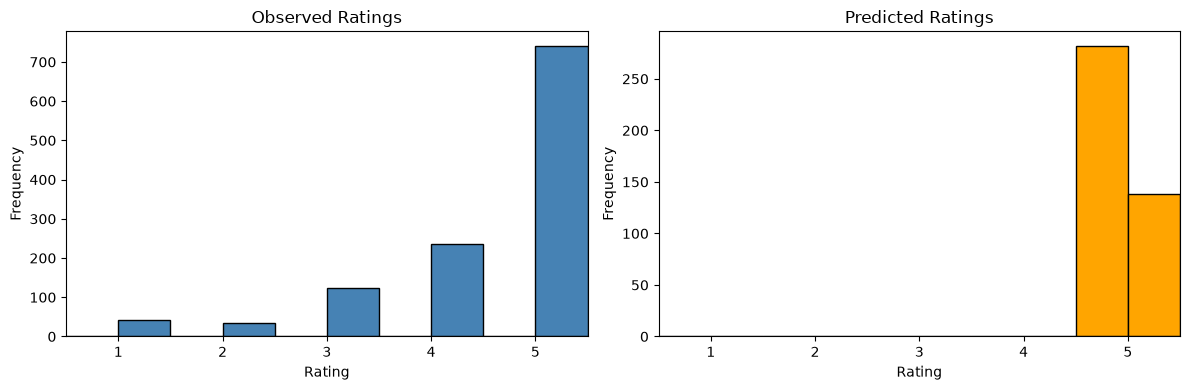

In [56]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bins = np.arange(0.5, 6.0, 0.5)

axes[0].hist(observed_ratings, bins=bins,
             color="steelblue", edgecolor="black")
axes[0].set_title("Observed Ratings")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Frequency")
axes[0].set_xlim(0.5, 5.5)

axes[1].hist(predicted_ratings, bins=bins,
             color="orange", edgecolor="black")
axes[1].set_title("Predicted Ratings")
axes[1].set_xlabel("Rating")
axes[1].set_ylabel("Frequency")
axes[1].set_xlim(0.5, 5.5)

plt.tight_layout()
plt.show()


<font size = "5">

Try it yourself!

- What happens if you change the minimum frequency of words <br>
and/or change the number of components?

In [52]:
# Write your own code



